In [1]:
import numpy as np
import anndata as ad
import pandas as pd
import scanpy as sc
import scipy
import os
import seaborn as sns
import matplotlib as mpl
from matplotlib import rcParams
import matplotlib.pyplot as plt
import gc
from scipy.stats import pearsonr
import os
import scanpy as sc
import muon as mu
from scipy.sparse import issparse, csr_matrix
from typing import Optional
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm

from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.sparse import issparse
from scipy.spatial import distance_matrix
import warnings

warnings.filterwarnings("ignore")

gc.enable()

/home/in68/miniconda3/envs/cell2loc_env/lib/python3.9/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/in68/miniconda3/envs/cell2loc_env/lib/python3.9/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/in68/miniconda3/envs/cell2loc_env/lib/python3.9/site-pac

In [17]:
from utility_scripts import *

## Databases: 

In [3]:
#Load and process the gene annotation file to use metadata for analysis e.g. Biotype % calculations
# Read the .tsv file
gtf_info = pd.read_csv("/workdir/in68/micro_STRS_github/backup/Low_resolution/Annotation_files/GRCm39_GENCODEM32_ReoT1L_gene_info_gtf.tsv", sep="\t")
gtf_info = gtf_info.drop_duplicates(subset=['GENEID'], keep='first')

# Remove period/decimal suffixes from ensembl IDs
gtf_info['GeneID'] = gtf_info['GENEID'].str.split('.').str[0]

# Extract chromosome value before the colon
gtf_info['chr'] = gtf_info['Chromosome'].str.split(':').str[0]

# Add '.1' to the Reovirus gene names to match the gtf file...
gtf_info["GENEID"] = [f"{GENE}.1" if 'T1LReovirus' in GENE else GENE for GENE in gtf_info['GENEID']]

print(f"Using {len(gtf_info['GENEID'].unique())} ensembl IDs, from {gtf_info['GeneSymbol'].nunique()} genes, and {gtf_info['Biotype'].nunique()} biotypes...\n")

# Display the first few rows
print(gtf_info.head())



#Add NCBI taxonomic ID file as dataframe to build taxonomic-level specific adata objects 
taxid = pd.read_csv('/workdir/in68/micro_STRS_github/backup/Low_resolution/Annotation_files/ncbi_lineages_2024-01-19.csv')
Taxonomic_df = taxid.copy()
def add_prefix(x):
    return f'taxid_{x}'

# Applying function to 'tax_id' column
Taxonomic_df['tax_id'] = Taxonomic_df['tax_id'].apply(add_prefix)

# Display the updated DataFrame
print(Taxonomic_df.head())

Using 56973 ensembl IDs, from 56825 genes, and 38 biotypes...

                 GENEID     GeneSymbol            Chromosome  \
0  ENSMUSG00000102693.2  4933401J01Rik  chr1:3143476-3144545   
1  ENSMUSG00000064842.3        Gm26206  chr1:3172239-3172348   
2  ENSMUSG00000051951.6           Xkr4  chr1:3276124-3741721   
3  ENSMUSG00000102851.2        Gm18956  chr1:3322980-3323459   
4  ENSMUSG00000103377.2        Gm37180  chr1:3435954-3438772   

                Biotype Strand              GeneID   chr  
0                   TEC      +  ENSMUSG00000102693  chr1  
1                 snRNA      +  ENSMUSG00000064842  chr1  
2        protein_coding      -  ENSMUSG00000051951  chr1  
3  processed_pseudogene      +  ENSMUSG00000102851  chr1  
4                   TEC      -  ENSMUSG00000103377  chr1  
    tax_id superkingdom          phylum                class  \
0  taxid_1          NaN             NaN                  NaN   
1  taxid_2     Bacteria             NaN                  NaN   
2  tax

In [4]:
taxid_to_delete = ['taxid_1', 'taxid_10090', 'taxid_119060', 'taxid_1211813', 'taxid_1224',
       'taxid_1236', 'taxid_1239', 'taxid_1268', 'taxid_1269', 'taxid_1279',
       'taxid_1280', 'taxid_1301', 'taxid_131567', 'taxid_1351', 'taxid_1385',
       'taxid_1396', 'taxid_1491', 'taxid_153135', 'taxid_1624',
       'taxid_165779', 'taxid_1716', 'taxid_1745854', 'taxid_1747',
       'taxid_1760', 'taxid_1783272', 'taxid_1789224', 'taxid_1853699',
       'taxid_186817', 'taxid_1883', 'taxid_190721', 'taxid_1912216',
       'taxid_191302', 'taxid_1916956', 'taxid_2', 'taxid_201174',
       'taxid_2049881', 'taxid_2184519', 'taxid_2306583', 'taxid_2618356',
       'taxid_2654547', 'taxid_2712222', 'taxid_2722752', 'taxid_2726118',
       'taxid_2782662', 'taxid_28211', 'taxid_28216', 'taxid_286',
       'taxid_2862880', 'taxid_2892442', 'taxid_2986923', 'taxid_2986930',
       'taxid_314146', 'taxid_31957', 'taxid_31989', 'taxid_32207',
       'taxid_33011', 'taxid_33958', 'taxid_358', 'taxid_36845', 'taxid_40324',
       'taxid_42906', 'taxid_43675', 'taxid_44283', 'taxid_446469',
       'taxid_465541', 'taxid_469', 'taxid_471', 'taxid_48736', 'taxid_524884',
       'taxid_525919', 'taxid_543', 'taxid_55601', 'taxid_564137', 'taxid_570',
       'taxid_573', 'taxid_59732', 'taxid_80840', 'taxid_82541', 'taxid_85006',
       'taxid_881', 'taxid_91061', 'taxid_91347', 'taxid_93386', 'taxid_9606',
       'taxid_976']

In [5]:
# Load the taxonomic identifiers for bacteria from a DataFrame
bacteria_taxids = Taxonomic_df[Taxonomic_df['superkingdom'] == 'Bacteria']['tax_id']
viruses_taxids = Taxonomic_df[Taxonomic_df['superkingdom'] == 'Viruses']['tax_id']
archaea_taxids = Taxonomic_df[Taxonomic_df['superkingdom'] == 'Archaea']['tax_id']

# Define the base directory where the host and microbial data are stored
base_dir = "/workdir/in68/microSTRS/subsampling/"
spatial_coord_path = "/workdir/lt425/202403_visium/visium-v1_coordinates.txt"
# List all the sample identifiers
samples = [f"STRS_A_{fraction}" for fraction in ['0.1', '0.25', '0.5', '0.75', '1.0']] + \
[f"STRS_B_{fraction}" for fraction in ['0.1', '0.25', '0.5', '0.75', '1.0']] + \
[f"STRS_C_{fraction}" for fraction in ['0.1', '0.25', '0.5', '0.75', '1.0']] + \
[f"STRS_D_{fraction}" for fraction in ['0.1', '0.25', '0.5', '0.75', '1.0']] + \
[f"Visium_A_{fraction}" for fraction in ['0.1', '0.25', '0.5', '0.75', '1.0']] + \
[f"Visium_B_{fraction}" for fraction in ['0.1', '0.25', '0.5', '0.75', '1.0']] + \
[f"Visium_C_{fraction}" for fraction in ['0.1', '0.25', '0.5', '0.75', '1.0']] + \
[f"Visium_D_{fraction}" for fraction in ['0.1', '0.25', '0.5', '0.75', '1.0']]
mudata_dict = {}

# Process data for each sample
for sample in samples:
    try:
        # Assemble the directory path for the host data for the current sample
        host_data_dir = os.path.join(base_dir, f"Sample_{sample}_solo/Solo.out/GeneFull/raw/")

        
        # Check if the host data directory exists; skip the sample if it doesn't
        if not os.path.exists(host_data_dir):
            print(f"Host data directory does not exist: {host_data_dir}")
            continue

        # Read the host gene expression data using the 10x Genomics format
        adata_host = sc.read_10x_mtx(host_data_dir, var_names='gene_symbols')
        adata_host_multimappers = sc.read_mtx(f"{host_data_dir}UniqueAndMult-EM.mtx.gz")
        adata_host.X = adata_host_multimappers.X.T
        adata_host = normalize_spatial_coordinates(adata_host, spatial_coord_path)
        adata_host.raw = adata_host.copy()
        # Add biotypes percentage and total counts to the host data
        add_biotypes_pct(adata_host, gtf_info)
        adata_host.obs['Total_counts'] = adata_host.X.sum(axis=1)
        
        
        # Construct the path for microbial data and verify it
        microbial_data_path = os.path.join(base_dir, f"Sample_{sample}_solo/microbe.h5ad")
        
        # Check if the microbial data file exists; skip the sample if it doesn't
        if not os.path.exists(microbial_data_path):
            print(f"Microbial data file does not exist: {microbial_data_path}")
            continue

        # Read the microbial data
        adata_unmapped = sc.read_h5ad(microbial_data_path)
        adata_unmapped = normalize_spatial_coordinates(adata_unmapped, spatial_coord_path)

        # Store the raw microbial data
        adata_unmapped.raw = adata_unmapped.copy()
        taxonomy_tmp = Taxonomic_df.copy()
        adata_unmapped.obs['Total_counts_unfiltered'] = adata_unmapped.X.sum(axis=1)

        # Filter the microbial data to include only bacteria
        mask = adata_unmapped.var.index.isin(bacteria_taxids)
        adata_bacteria = adata_unmapped[:, mask].copy()
        adata_bacteria.obs['Total_counts_unfiltered'] = adata_bacteria.X.sum(axis=1)

        # Delete the taxids that are found in controls
        mask2 = adata_bacteria.var.index.isin(taxid_to_delete)
        adata_bacteria = adata_bacteria[:, ~mask2].copy()


        
        # Filter the microbial data to include only virus
        mask = adata_unmapped.var.index.isin(viruses_taxids)
        adata_virus = adata_unmapped[:, mask].copy()
        adata_virus.obs['Total_counts_unfiltered'] = adata_virus.X.sum(axis=1)

        # Delete the taxids that are found in controls from virus
        mask2 = adata_virus.var.index.isin(taxid_to_delete)
        adata_virus = adata_virus[:, ~mask2].copy()
        adata_virus.obs['Total_counts'] = adata_virus.X.sum(axis=1)


        
        # Filter the microbial data to include only ARCHAEA
        mask = adata_unmapped.var.index.isin(archaea_taxids)
        adata_archaea = adata_unmapped[:, mask].copy()
        adata_archaea.obs['Total_counts_unfiltered'] = adata_archaea.X.sum(axis=1)

        # Delete the taxids that are found in controls from virus
        mask2 = adata_archaea.var.index.isin(taxid_to_delete)
        adata_archaea = adata_archaea[:, ~mask2].copy()
        adata_archaea.obs['Total_counts'] = adata_archaea.X.sum(axis=1)


        
        adata_host.obs['Total_molecules_detected'] = adata_host.obs['Total_counts'] + adata_unmapped.obs['Total_counts_unfiltered']
        adatas = {'host': adata_host, 'bacteria': adata_bacteria.copy(),
                  'viruses': adata_virus.copy(),'archaea': adata_archaea.copy(), 
                  'unmapped_all': adata_unmapped.copy()}



        
        # Process each taxonomic level bacteria
        for tax_level in ['species', 'genus', 'family', 'phylum']:
            # adata_bacteria.uns['taxonomy'][tax_level] = adata_ba el].fillna('unclassified')
            tax_id_to_name = dict(zip(Taxonomic_df['tax_id'], Taxonomic_df[tax_level]))
            adata_bacteria.var[tax_level] = adata_bacteria.var.index.map(tax_id_to_name).fillna('unclassified')
            adata_df = pd.DataFrame(adata_bacteria.X.toarray(), columns=adata_bacteria.var[tax_level])
            aggregated_data = adata_df.groupby(adata_df.columns, axis=1).sum()

            new_vars = pd.DataFrame(index=aggregated_data.columns)
            X_mat = csr_matrix(np.round(aggregated_data.values).astype(np.float32))

            new_adata_bacteria = sc.AnnData(X=X_mat, var=new_vars, obs=adata_bacteria.obs)

            # Add the raw component
            new_adata_bacteria.raw = new_adata_bacteria.copy()

            new_adata_bacteria.obs['Total_counts'] = new_adata_bacteria.X.sum(axis=1)
            unclassified_mask = new_adata_bacteria.var.index == 'unclassified'
            new_adata_bacteria.obs['Total_counts_unclassified'] = new_adata_bacteria[:, unclassified_mask].X.sum(axis=1)
            new_adata_bacteria.obs['Total_counts_classified'] = new_adata_bacteria.obs['Total_counts'] - new_adata_bacteria.obs['Total_counts_unclassified']
            # Filtering step after calculating Total_counts
            # total_counts = new_adata_bacteria.obs['Total_counts'].sum()
            # taxon_percentages = new_adata_bacteria.X.sum(axis=0) / total_counts * 100

            # # Identify taxa that are <= 0.01% and remove them
            # low_abundance_mask = taxon_percentages <= 0.01
            # new_adata_bacteria = new_adata_bacteria[:, ~low_abundance_mask].copy()
            # # Remove 'unclassified' variable if it exists
            # if 'unclassified' in new_adata_bacteria.var_names:
            #     unclassified_mask = new_adata_bacteria.var_names == 'unclassified'
            #     new_adata_bacteria = new_adata_bacteria[:, ~unclassified_mask].copy()


            
            # Normalize counts and log transform
            total_microbial_counts = new_adata_bacteria.X.sum()
            new_adata_bacteria.X = new_adata_bacteria.X / total_microbial_counts * 10000
            new_adata_bacteria = normalize_spatial_coordinates(new_adata_bacteria, spatial_coord_path)
            spot_counts = new_adata_bacteria.X > 0
            unique_genes_per_spot = spot_counts.sum(axis=1)
            new_adata_bacteria.obs['unique_taxa_per_spot'] = unique_genes_per_spot
            sc.pp.log1p(new_adata_bacteria)

            adatas[tax_level] = new_adata_bacteria
            # Delete intermediate variables to free up memory
            del adata_df, aggregated_data, new_vars, X_mat, new_adata_bacteria, tax_id_to_name
       

        # Process each taxonomic level for virus
        for tax_level in ['species', 'genus', 'family', 'phylum']:
            # adata_virus.uns['taxonomy'][tax_level] = adata_virus.uns['taxonomy'][tax_level].fillna('unclassified')
            tax_id_to_name = dict(zip(Taxonomic_df['tax_id'], Taxonomic_df[tax_level]))
            adata_virus.var[tax_level] = adata_virus.var.index.map(tax_id_to_name).fillna('unclassified')
            adata_df = pd.DataFrame(adata_virus.X.toarray(), columns=adata_virus.var[tax_level])
            aggregated_data = adata_df.groupby(adata_df.columns, axis=1).sum()

            new_vars = pd.DataFrame(index=aggregated_data.columns)
            X_mat = csr_matrix(np.round(aggregated_data.values).astype(np.float32))

            new_adata_virus = sc.AnnData(X=X_mat, var=new_vars, obs=adata_virus.obs)

            # Add the raw component
            new_adata_virus.raw = new_adata_virus.copy()

            new_adata_virus.obs['Total_counts'] = new_adata_virus.X.sum(axis=1)
            unclassified_mask = new_adata_virus.var.index == 'unclassified'
            new_adata_virus.obs['Total_counts_unclassified'] = new_adata_virus[:, unclassified_mask].X.sum(axis=1)
            new_adata_virus.obs['Total_counts_classified'] = new_adata_virus.obs['Total_counts'] - new_adata_virus.obs['Total_counts_unclassified']

            # Normalize counts and log transform
            total_microbial_counts = new_adata_virus.X.sum()
            new_adata_virus.X = new_adata_virus.X / total_microbial_counts * 10000
            new_adata_virus = normalize_spatial_coordinates(new_adata_virus, spatial_coord_path)
            spot_counts = new_adata_virus.X > 0
            unique_genes_per_spot = spot_counts.sum(axis=1)
            new_adata_virus.obs['unique_taxa_per_spot'] = unique_genes_per_spot
            sc.pp.log1p(new_adata_virus)
            tax_level_to_use = f"{tax_level}_virus"
            adatas[tax_level_to_use] = new_adata_virus
            # Delete intermediate variables to free up memory
            del adata_df, aggregated_data, new_vars, X_mat, new_adata_virus, tax_id_to_name
            
        # Process each taxonomic level for archaea
        for tax_level in ['species', 'genus', 'family', 'phylum']:
            # adata_archaea.uns['taxonomy'][tax_level] = adata_archaea.uns['taxonomy'][tax_level].fillna('unclassified')
            tax_id_to_name = dict(zip(Taxonomic_df['tax_id'], Taxonomic_df[tax_level]))
            adata_archaea.var[tax_level] = adata_archaea.var.index.map(tax_id_to_name).fillna('unclassified')
            adata_df = pd.DataFrame(adata_archaea.X.toarray(), columns=adata_archaea.var[tax_level])
            aggregated_data = adata_df.groupby(adata_df.columns, axis=1).sum()

            new_vars = pd.DataFrame(index=aggregated_data.columns)
            X_mat = csr_matrix(np.round(aggregated_data.values).astype(np.float32))

            new_adata_archaea = sc.AnnData(X=X_mat, var=new_vars, obs=adata_archaea.obs)

            # Add the raw component
            new_adata_archaea.raw = new_adata_archaea.copy()

            new_adata_archaea.obs['Total_counts'] = new_adata_archaea.X.sum(axis=1)
            unclassified_mask = new_adata_archaea.var.index == 'unclassified'
            new_adata_archaea.obs['Total_counts_unclassified'] = new_adata_archaea[:, unclassified_mask].X.sum(axis=1)
            new_adata_archaea.obs['Total_counts_classified'] = new_adata_archaea.obs['Total_counts'] - new_adata_archaea.obs['Total_counts_unclassified']

            # Normalize counts and log transform
            total_microbial_counts = new_adata_archaea.X.sum()
            new_adata_archaea.X = new_adata_archaea.X / total_microbial_counts * 10000
            new_adata_archaea = normalize_spatial_coordinates(new_adata_archaea, spatial_coord_path)
            spot_counts = new_adata_archaea.X > 0
            unique_genes_per_spot = spot_counts.sum(axis=1)
            new_adata_archaea.obs['unique_taxa_per_spot'] = unique_genes_per_spot
            sc.pp.log1p(new_adata_archaea)
            tax_level_to_use = f"{tax_level}_archaea"
            adatas[tax_level_to_use] = new_adata_archaea



            
            # Delete intermediate variables to free up memory
            del adata_df, aggregated_data, new_vars, X_mat, new_adata_archaea, tax_id_to_name

        # Store the combined data object for each sample
        mudata_dict[sample] = mu.MuData(adatas)

        # Delete intermediate variables to free up memory
        del adata_host, adata_unmapped, adata_bacteria, adatas, mask, mask2

    except Exception as e:
        print(f"An error occurred while processing sample {sample}: {e}")

# Output which samples have been successfully processed
print("Processed samples:", list(mudata_dict.keys()))
gc.collect()


Added spatial coordinates for 4992 cells.
No gene_version1 genes found...
Added spatial coordinates for 4988 cells.
Added spatial coordinates for 4988 cells.
Added spatial coordinates for 4988 cells.
Added spatial coordinates for 4988 cells.
Added spatial coordinates for 4988 cells.
Added spatial coordinates for 4988 cells.
Added spatial coordinates for 4988 cells.
Added spatial coordinates for 4988 cells.
Added spatial coordinates for 4988 cells.
Added spatial coordinates for 4988 cells.
Added spatial coordinates for 4988 cells.
Added spatial coordinates for 4988 cells.
Added spatial coordinates for 4988 cells.
Added spatial coordinates for 4992 cells.
No gene_version1 genes found...
Added spatial coordinates for 4990 cells.
Added spatial coordinates for 4990 cells.
Added spatial coordinates for 4990 cells.
Added spatial coordinates for 4990 cells.
Added spatial coordinates for 4990 cells.
Added spatial coordinates for 4990 cells.
Added spatial coordinates for 4990 cells.
Added spatia

3085

🔎 Fetching read counts...
✅ Loaded read counts for 40 samples

🧮 Calculating metrics from mudata_dict...
✅ Metric collection complete

📊 Plotting saturation curves...


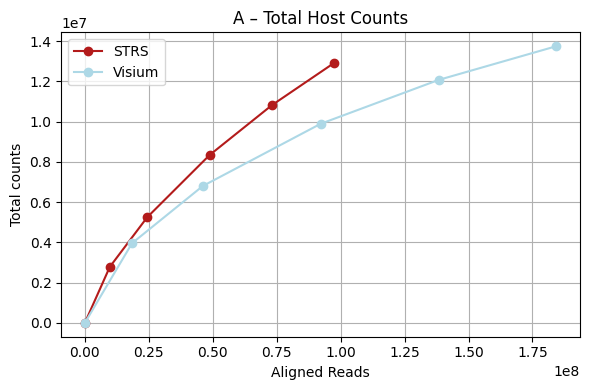

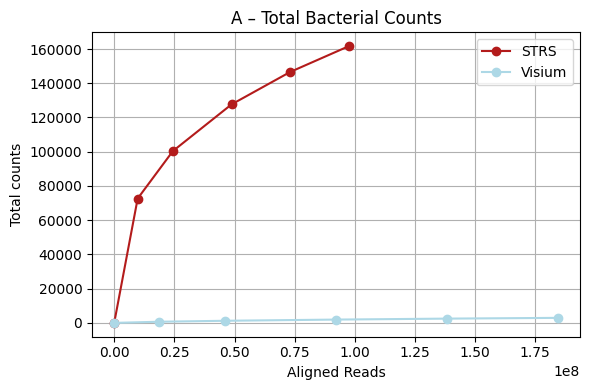

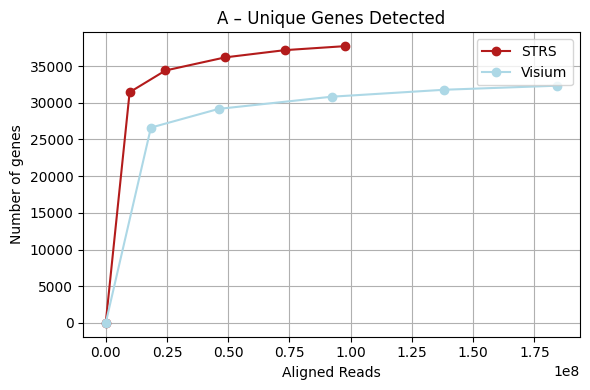

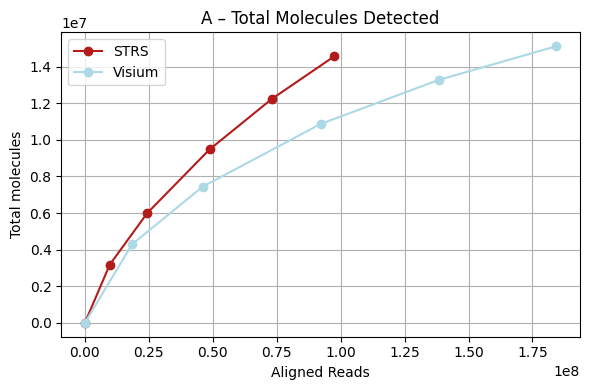

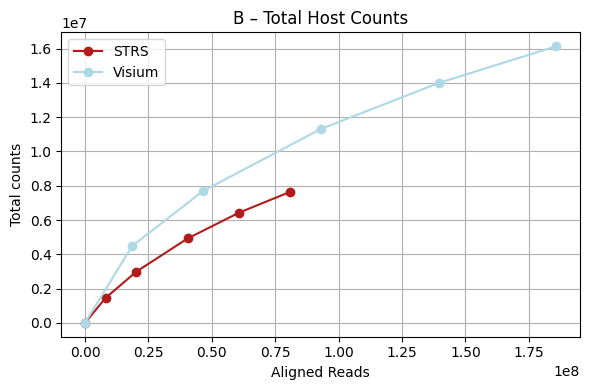

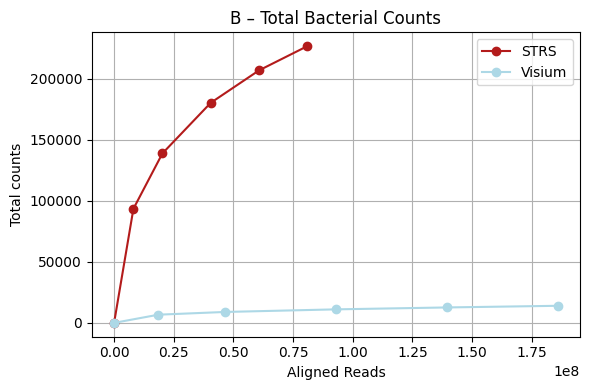

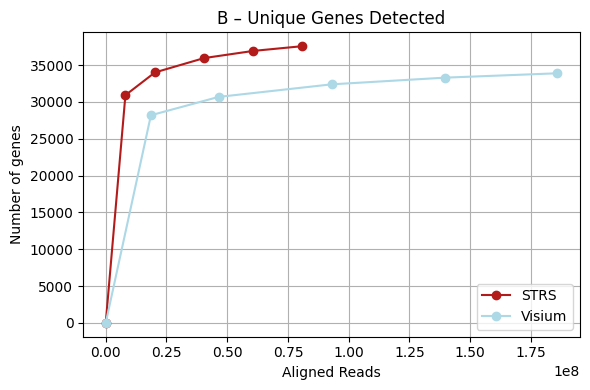

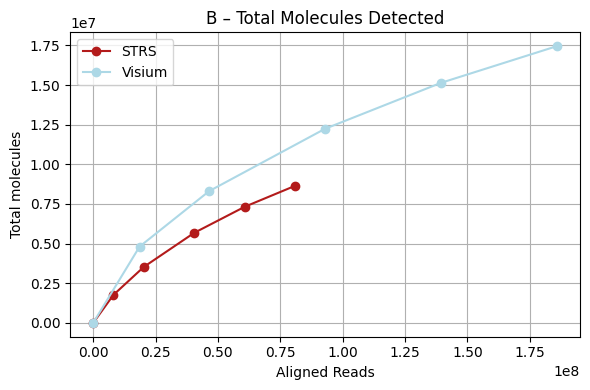

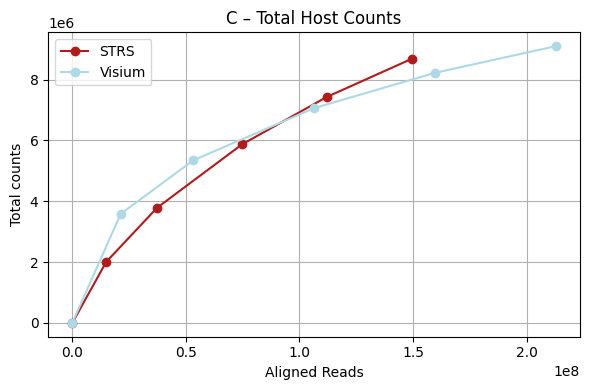

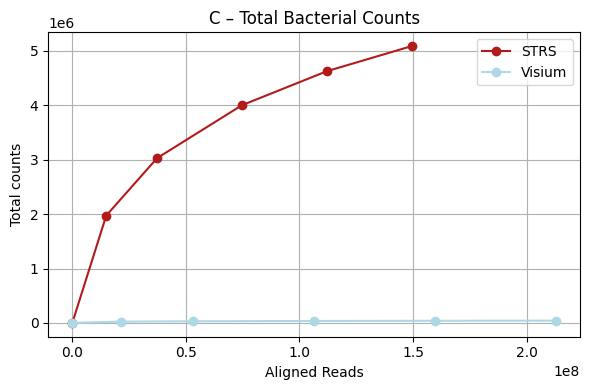

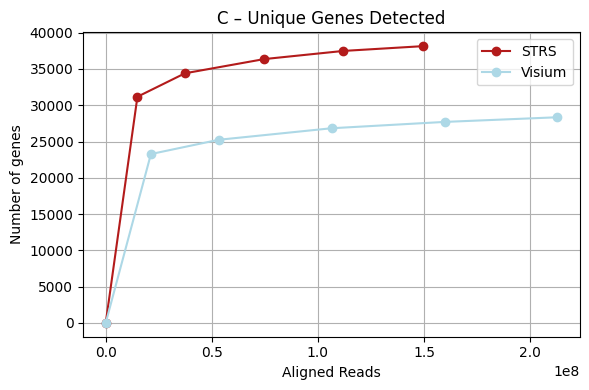

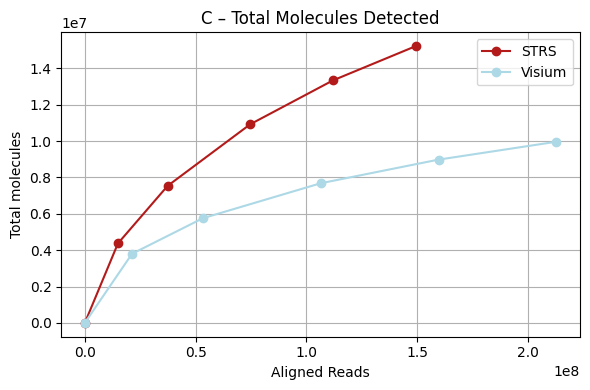

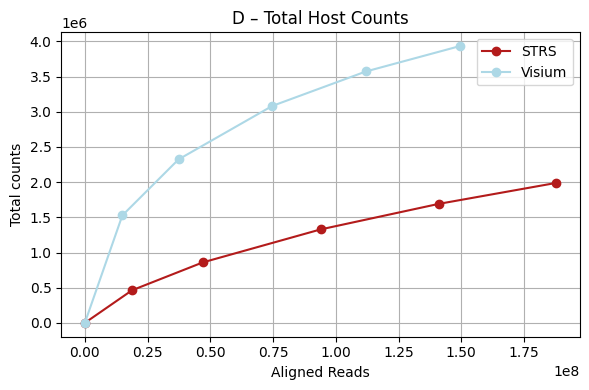

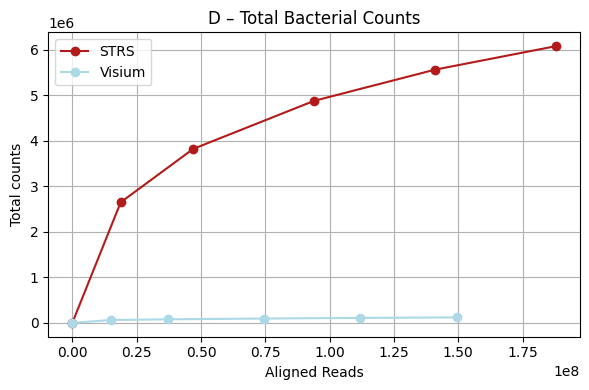

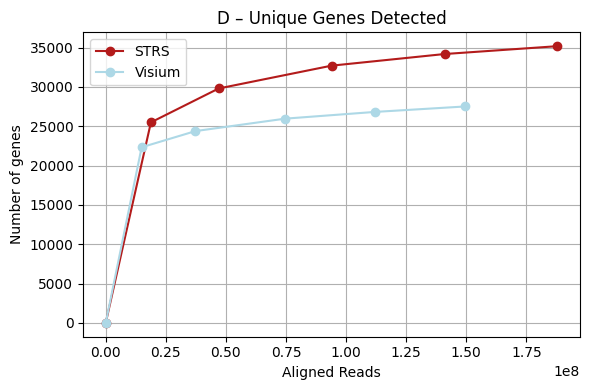

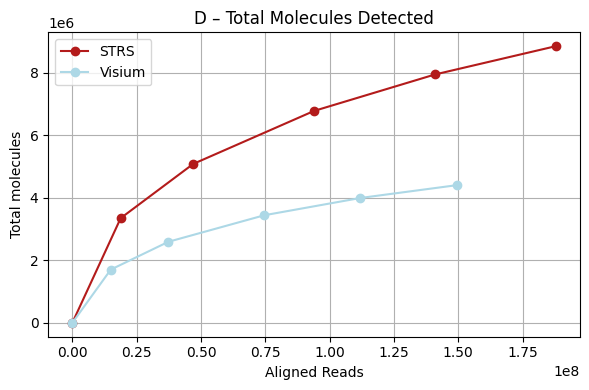


🧪 Fitting Michaelis-Menten to 'total_molecules_detected'...

📈 A_STRS: Vmax = 27.05, Km = 86.44


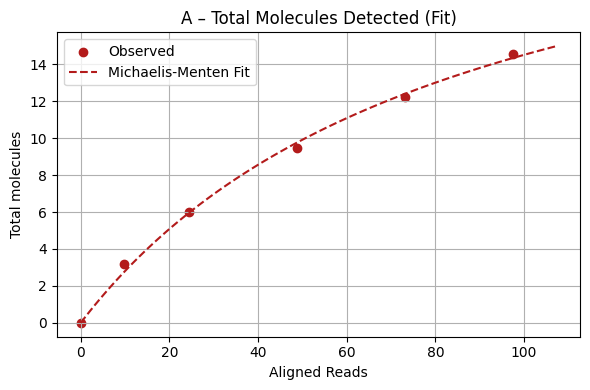

📈 A_Visium: Vmax = 21.92, Km = 88.14


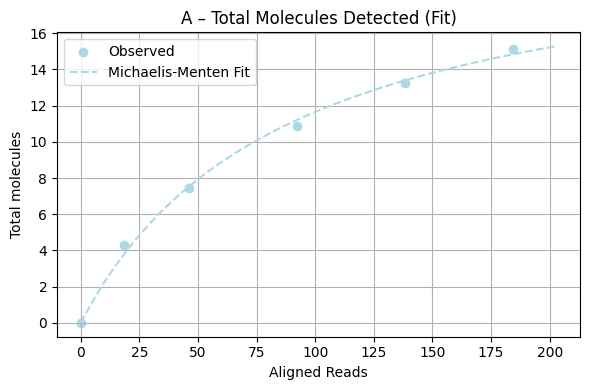

📈 B_STRS: Vmax = 16.54, Km = 75.33


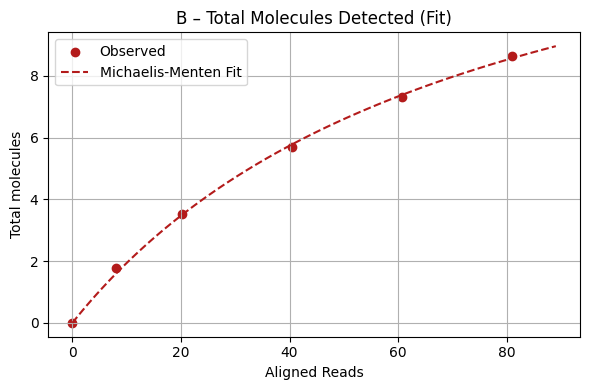

📈 B_Visium: Vmax = 26.12, Km = 98.33


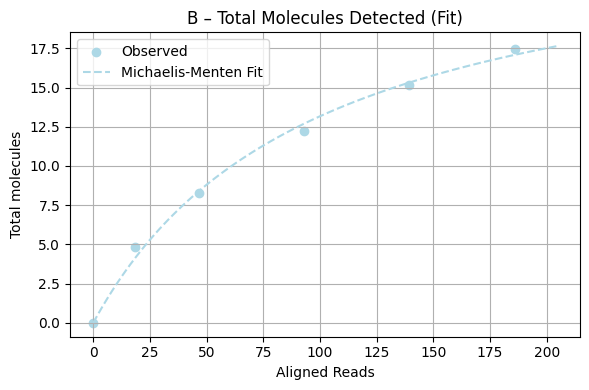

📈 C_STRS: Vmax = 21.90, Km = 70.12


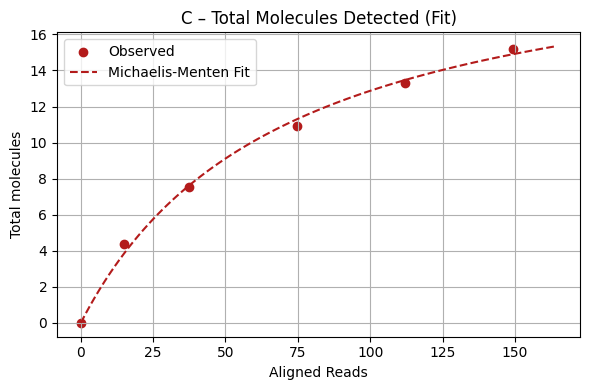

📈 C_Visium: Vmax = 12.19, Km = 55.75


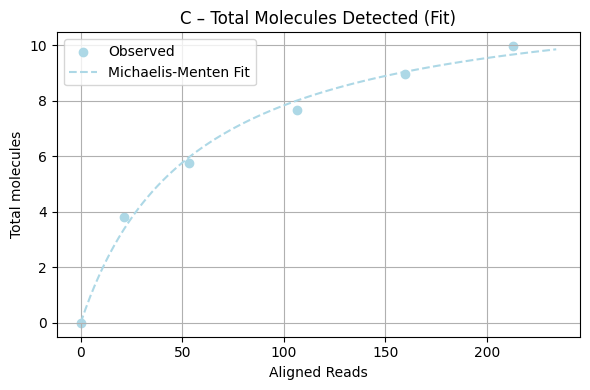

📈 D_STRS: Vmax = 10.85, Km = 50.08


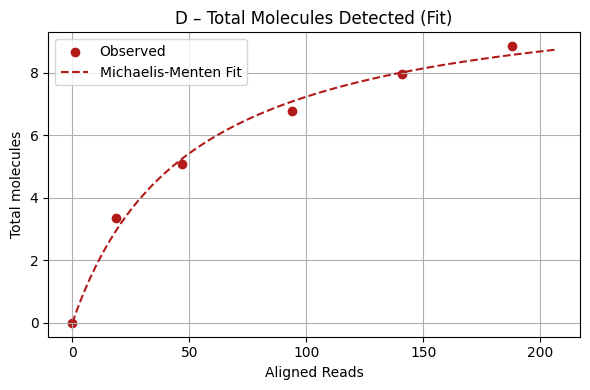

📈 D_Visium: Vmax = 5.35, Km = 37.19


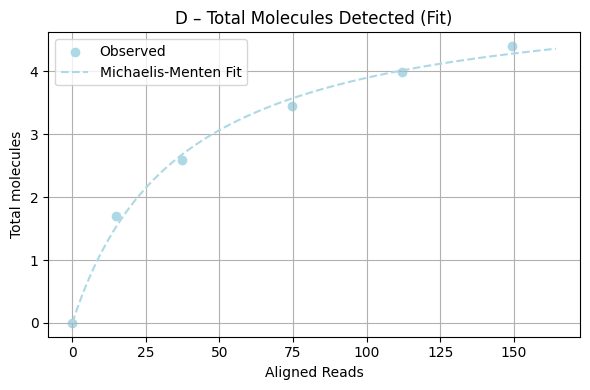

In [6]:
%matplotlib inline 

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

# -------------------- STEP 1: Load Read Counts -------------------- #

fractions_str = ['0.1', '0.25', '0.5', '0.75', '1.0']
platforms = ["STRS", "Visium"]
sides = ["A", "B", "C", "D"]
base_dir = "/workdir/in68/microSTRS/subsampling/"
samples = [f"{platform}_{side}_{frac}" for platform in platforms for side in sides for frac in fractions_str]
reads_summary = {}

print("🔎 Fetching read counts...")
for sample in samples:
    summary_file_path = os.path.join(base_dir, f"Sample_{sample}_solo/Solo.out/GeneFull/Summary.csv")
    if os.path.exists(summary_file_path):
        try:
            df = pd.read_csv(summary_file_path, header=None)
            df = df.T
            df.columns = df.iloc[0]
            df = df.drop(df.index[0])
            if "Number of Reads" in df.columns:
                reads_summary[sample] = float(pd.to_numeric(df["Number of Reads"].values[0], errors='coerce'))
            else:
                print(f"[WARN] Column 'Number of Reads' not found in {sample}")
        except Exception as e:
            print(f"[ERROR] Failed to parse Summary.csv for {sample}: {e}")
    else:
        print(f"[MISSING FILE] {summary_file_path}")

read_count_lookup = {k: v for k, v in reads_summary.items() if pd.notna(v)}
print(f"✅ Loaded read counts for {len(read_count_lookup)} samples\n")

# -------------------- STEP 2: Compute Metrics -------------------- #

print("🧮 Calculating metrics from mudata_dict...")
platform_colors = {"STRS": "#B31B1B", "Visium": "#ADD8E6"}
metric_data = {
    "total_host": {}, 
    "total_bacteria": {}, 
    "total_molecules_detected": {}, 
    "unique_genes": {}
}

for sample in sides:
    for platform in platforms:
        key = f"{sample}_{platform}"
        total_host, total_bacteria = [], []
        total_molecules_detected, unique_genes = [], []

        for frac in fractions_str:
            fkey = f"{platform}_{sample}_{frac}"
            if fkey not in mudata_dict:
                print(f"[SKIP] Missing mudata_dict for: {fkey}")
                total_host.append(np.nan)
                total_bacteria.append(np.nan)
                total_molecules_detected.append(np.nan)
                unique_genes.append(np.nan)
                continue

            md = mudata_dict[fkey]
            host = md.mod["host"]
            bacteria = md.mod["phylum"]

            # Total host counts
            total_host.append(host.obs["Total_counts"].sum())

            # Total bacterial counts
            total_bacteria.append(bacteria.obs["Total_counts"].sum())

            # Total molecules detected
            total_mol = host.obs["Total_molecules_detected"].sum() if "Total_molecules_detected" in host.obs else np.nan
            total_molecules_detected.append(total_mol)

            # Unique genes detected
            host_matrix = host.X.toarray() if hasattr(host.X, 'toarray') else host.X
            unique = (host_matrix.sum(axis=0) > 0).sum()
            unique = unique.A1[0] if hasattr(unique, "A1") else int(unique)
            unique_genes.append(unique)

        metric_data["total_host"][key] = total_host
        metric_data["total_bacteria"][key] = total_bacteria
        metric_data["total_molecules_detected"][key] = total_molecules_detected
        metric_data["unique_genes"][key] = unique_genes

print("✅ Metric collection complete\n")

# -------------------- STEP 3: Plot Saturation Curves -------------------- #

print("📊 Plotting saturation curves...")
plot_configs = [
    ("total_host", "Total Host Counts", "Total counts"),
    ("total_bacteria", "Total Bacterial Counts", "Total counts"),
    ("unique_genes", "Unique Genes Detected", "Number of genes"),
    ("total_molecules_detected", "Total Molecules Detected", "Total molecules"),
]

for sample in sides:
    for metric, title, ylabel in plot_configs:
        plt.figure(figsize=(6, 4))
        plotted = False

        for platform in platforms:
            mkey = f"{sample}_{platform}"
            yvals = metric_data[metric].get(mkey, [])
            snames = [f"{platform}_{sample}_{frac}" for frac in fractions_str]

            xvals_clean, yvals_clean = [], []
            for i, sname in enumerate(snames):
                rc = read_count_lookup.get(sname, np.nan)
                yval = yvals[i] if i < len(yvals) else np.nan
                if not np.isnan(rc) and not np.isnan(yval):
                    xvals_clean.append(rc)
                    yvals_clean.append(yval)

            xvals_clean.insert(0, 0)
            yvals_clean.insert(0, 0)

            if len(xvals_clean) < 2:
                continue

            x = np.array(xvals_clean)
            y = np.array(yvals_clean)
            plt.plot(np.sort(x), np.array(y)[np.argsort(x)], marker='o', color=platform_colors[platform], label=platform)
            plotted = True

        if not plotted:
            plt.close()
            continue

        plt.title(f"{sample} – {title}")
        plt.xlabel("Aligned Reads")
        plt.ylabel(ylabel)
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

# -------------------- STEP 4: Fit Michaelis-Menten -------------------- #

def michaelis_menten(x, Vmax, Km):
    return (Vmax * x) / (Km + x)

print("\n🧪 Fitting Michaelis-Menten to 'total_molecules_detected'...\n")
for sample in sides:
    for platform in platforms:
        mkey = f"{sample}_{platform}"
        yvals = metric_data["total_molecules_detected"].get(mkey, [])
        snames = [f"{platform}_{sample}_{frac}" for frac in fractions_str]

        xvals_clean, yvals_clean = [], []
        for i, sname in enumerate(snames):
            rc = read_count_lookup.get(sname, np.nan)
            yval = yvals[i] if i < len(yvals) else np.nan
            if not np.isnan(rc) and not np.isnan(yval):
                xvals_clean.append(rc)
                yvals_clean.append(yval)

        xvals_clean.insert(0, 0)
        yvals_clean.insert(0, 0)

        xvals_clean = np.array(xvals_clean) / 1e6  # Convert to millions
        yvals_clean = np.array(yvals_clean) / 1e6  # Convert to millions
        
        x = np.array(xvals_clean)
        y = np.array(yvals_clean)
        if len(x) < 4:
            print(f"[SKIP] Not enough points for {mkey}")
            continue

        try:
            popt, _ = curve_fit(michaelis_menten, x, y, bounds=(0, np.inf))
            Vmax, Km = popt
            print(f"📈 {mkey}: Vmax = {Vmax:.2f}, Km = {Km:.2f}")

            xfit = np.linspace(0, max(x)*1.1, 100)
            yfit = michaelis_menten(xfit, Vmax, Km)

            plt.figure(figsize=(6, 4))
            plt.scatter(x, y, label="Observed", color=platform_colors[platform])
            plt.plot(xfit, yfit, linestyle='--', color=platform_colors[platform], label="Michaelis-Menten Fit")
            plt.title(f"{sample} – Total Molecules Detected (Fit)")
            plt.xlabel("Aligned Reads")
            plt.ylabel("Total molecules")
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()
        except Exception as e:
            print(f"[FAIL] Curve fitting failed for {mkey}: {e}")


In [30]:
import matplotlib
# matplotlib.use("Agg")
%matplotlib inline
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import numpy as np
import os

def michaelis_menten(x, Vmax, Km):
    return (Vmax * x) / (Km + x)

save_dir = "/fs/cbsuvlaminck5/workdir/in68/microstrs_rebuttal/figs"
os.makedirs(save_dir, exist_ok=True)
side_dict = {"A": "SI", "B": "IL", "C": "CO", "D": "CE"}

metric_titles = {
    "total_host": "Host: Total Counts",
    "total_bacteria": "Bacteria: Total Counts",
    "unique_genes": "Host: Unique Genes Detected",
    "total_molecules_detected": "Host: Total Molecules Detected"
}

for metric, title in metric_titles.items():
    fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(6, 2), sharey=True)

    # Collect global axis limits
    all_x, all_y = [], []
    for side in sides:
        for platform in platforms:
            mkey = f"{side}_{platform}"
            yvals = metric_data[metric].get(mkey, [])
            snames = [f"{platform}_{side}_{frac}" for frac in fractions_str]
            for i, sname in enumerate(snames):
                rc = read_count_lookup.get(sname, np.nan)
                yval = yvals[i] if i < len(yvals) else np.nan
                if metric == "total_bacteria" and side in ["A", "B"]:
                    yval *= 10
                if not np.isnan(rc) and not np.isnan(yval):
                    all_x.append(rc)
                    all_y.append(yval)

    xlim = (0, np.nanmax(all_x) * 1.05 / 1e6)
    ylim = (0, np.nanmax(all_y) * 1.1)

    for col_idx, side in enumerate(sides):
        ax = axes[col_idx]
        for platform in platforms:
            mkey = f"{side}_{platform}"
            yvals = metric_data[metric].get(mkey, [])
            snames = [f"{platform}_{side}_{frac}" for frac in fractions_str]

            xvals_clean, yvals_clean = [], []
            for i, sname in enumerate(snames):
                rc = read_count_lookup.get(sname, np.nan)
                yval = yvals[i] if i < len(yvals) else np.nan
                if metric == "total_bacteria" and side in ["A", "B"]:
                    yval *= 10
                if not np.isnan(rc) and not np.isnan(yval):
                    xvals_clean.append(rc)
                    yvals_clean.append(yval)

            xvals_clean.insert(0, 0)
            xvals_clean = np.array(xvals_clean) / 1e6  # million reads
            yvals_clean.insert(0, 0)

            if len(xvals_clean) >= 3:
                x = np.array(xvals_clean)
                y = np.array(yvals_clean)
                sort = np.argsort(x)
                x_sorted = x[sort]
                y_sorted = y[sort]

                ax.plot(x_sorted, y_sorted, marker='o', label=platform,
                        color=platform_colors[platform], linewidth=0, markersize=2)

                try:
                    popt, _ = curve_fit(michaelis_menten, x_sorted, y_sorted,
                                        bounds=(0, [np.max(y_sorted)*10, np.max(x_sorted)*10]))
                    Vmax, Km = popt
                    x_fit = np.linspace(0, max(x_sorted)*6, 300)
                    y_fit = michaelis_menten(x_fit, *popt)
                    ax.plot(x_fit, y_fit, linestyle='--', color=platform_colors[platform], alpha=0.6, linewidth=1)

                    y_pred = michaelis_menten(x_sorted, *popt)
                    r2 = r2_score(y_sorted, y_pred)
                    Vmax_disp = Vmax /1e6
                    print(f"{platform}_{side} - Fit: Vmax = {Vmax_disp:.2f}, Km = {Km:.2f}, R² = {r2:.3f}")
                    print(f"Vmax = {Vmax_disp:.2f}")
                    print(f"Vmax = {Vmax}")
                    print(f"Km = {Km:.2f}")
                    print(f"R² = {r2:.3f}")
                    print("---------------------------------------------------------------------------------")
                except Exception as e:
                    print(f"Fit failed for {platform}_{side}: {e}")


        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.set_title(f"{side_dict[side]}", fontsize=8)
        ax.set_xlabel("Million Reads", fontsize=8)
        if col_idx == 0:
            ax.set_ylabel(title, fontsize=8)
        ax.tick_params(labelsize=6)
        ax.grid(False)

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    pdf_path = os.path.join(save_dir, f"{metric}_rarefaction.pdf")
    fig.savefig(pdf_path, format='pdf')
    plt.close(fig)


STRS_A - Fit: Vmax = 24.57, Km = 90.68, R² = 0.998
Vmax = 24.57
Vmax = 24566771.62163649
Km = 90.68
R² = 0.998
---------------------------------------------------------------------------------
Visium_A - Fit: Vmax = 19.81, Km = 86.42, R² = 0.997
Vmax = 19.81
Vmax = 19808112.936776236
Km = 86.42
R² = 0.997
---------------------------------------------------------------------------------
STRS_B - Fit: Vmax = 15.81, Km = 87.62, R² = 0.999
Vmax = 15.81
Vmax = 15805834.701761656
Km = 87.62
R² = 0.999
---------------------------------------------------------------------------------
Visium_B - Fit: Vmax = 24.09, Km = 97.78, R² = 0.996
Vmax = 24.09
Vmax = 24085603.708041757
Km = 97.78
R² = 0.996
---------------------------------------------------------------------------------
STRS_C - Fit: Vmax = 14.81, Km = 109.18, R² = 0.998
Vmax = 14.81
Vmax = 14811039.419729177
Km = 109.18
R² = 0.998
---------------------------------------------------------------------------------
Visium_C - Fit: Vmax = 10

In [ ]:
import matplotlib
matplotlib.use("Agg")
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# -------------------------------------- #
#          CONFIGURABLE PARAMS          #
# -------------------------------------- #
fractions_str = ['0.1', '0.25', '0.5', '0.75', '1.0']
platforms = ["STRS", "Visium"]
sides = ["A", "B", "C", "D"]
platform_colors = {"STRS": "#B31B1B", "Visium": "#ADD8E6"}
side_dict = {"A": "SI", "B": "IL", "C": "CO", "D": "CE"}
base_dir = "/workdir/in68/microSTRS/subsampling/"
save_dir = "/fs/cbsuvlaminck5/workdir/in68/microstrs_rebuttal/figs"
os.makedirs(save_dir, exist_ok=True)

def sat_curve(x, Km):
    return x / (Km + x)

# -------------------------------------- #
#          PARSE SUMMARY FILES          #
# -------------------------------------- #
summary_data = {}
for platform in platforms:
    for side in sides:
        for frac in fractions_str:
            sample = f"{platform}_{side}_{frac}"
            fpath = os.path.join(base_dir, f"Sample_{sample}_solo/Solo.out/GeneFull/Summary.csv")
            if not os.path.exists(fpath):
                continue
            try:
                df = pd.read_csv(fpath, header=None).T
                df.columns = df.iloc[0]
                df = df.drop(df.index[0])

                aligned_reads = float(df["Number of Reads"].values[0])
                map_frac_host = float(df["Reads Mapped to GeneFull: Unique+Multiple GeneFull"].values[0])
                valid_bcd = float(df["Reads With Valid Barcodes"].values[0])
                summary_data[sample] = {
                    "aligned_reads": aligned_reads,
                    "map_frac_host": map_frac_host,
                    "valid_bcd": valid_bcd
                }
            except Exception as e:
                print(f"[FAIL] {sample}: {e}")

# -------------------------------------- #
#         COMPUTE PROXY SATURATIONS     #
# -------------------------------------- #
host_saturation, bact_saturation, total_saturation = {}, {}, {}

for platform in platforms:
    for side in sides:
        sample_id = f"{side}_{platform}"
        host_vals, bact_vals, total_vals = [], [], []
        for frac in fractions_str:
            fkey = f"{platform}_{side}_{frac}"
            if fkey not in mudata_dict or fkey not in summary_data:
                host_vals.append(np.nan)
                bact_vals.append(np.nan)
                total_vals.append(np.nan)
                continue

            md = mudata_dict[fkey]
            aligned_reads = summary_data[fkey]["aligned_reads"] 
            host_reads = md.mod["host"].obs["Total_counts"].sum()
            total_mol = md.mod["host"].obs["Total_molecules_detected"].sum()
            host_map_frac = summary_data[fkey]["map_frac_host"]
            valid_bcd = summary_data[fkey]["valid_bcd"]

            total_sat = 1 - total_mol / (aligned_reads * valid_bcd) if aligned_reads > 0 else np.nan
            host_sat = 1 - (host_reads / (aligned_reads* valid_bcd * host_map_frac)) if host_map_frac > 0 else np.nan
            bact_sat = 1 - ((total_mol-host_reads) / (aligned_reads* valid_bcd * (1 - host_map_frac))) if (1 - host_map_frac) > 0 else np.nan

            host_vals.append(host_sat)
            bact_vals.append(bact_sat)
            total_vals.append(total_sat)

        host_saturation[sample_id] = host_vals
        bact_saturation[sample_id] = bact_vals
        total_saturation[sample_id] = total_vals

# -------------------------------------- #
#              PLOT PANELS              #
# -------------------------------------- #
saturation_dict = {
    "total": (total_saturation, "Total Proxy Sequencing Saturation"),
    "host": (host_saturation, "Host Proxy Sequencing Saturation"),
    "bacteria": (bact_saturation, "Bacterial Proxy Sequencing Saturation"),
}

for tag, (sat_data, title) in saturation_dict.items():
    fig, axes = plt.subplots(1, 4, figsize=(6, 2.5), sharey=True)

    for idx, side in enumerate(sides):
        ax = axes[idx]
        for platform in platforms:
            sample_id = f"{side}_{platform}"
            xs, ys = [], []
            for i, frac in enumerate(fractions_str):
                fkey = f"{platform}_{side}_{frac}"
                if fkey in summary_data:
                    xs.append(summary_data[fkey]["aligned_reads"])
                    ys.append(sat_data[sample_id][i])

            xs = np.array(xs)
            ys = np.array(ys)
            sort_idx = np.argsort(xs)
            xs = xs[sort_idx]
            ys = ys[sort_idx]
            # add (0,0) data point 
            xs = np.insert(xs, 0, 0)
            ys = np.insert(ys, 0, 0) 
            # Div by 1e6 to report in Million reads   
            xs = xs / 1e6

            if len(xs) >= 3:
                try:
                    Km, _ = curve_fit(sat_curve, xs, ys, bounds=(0, 1e2),p0=[1e1])
                    x_fit = np.linspace(0, 2.5e2, 400)
                    y_fit = sat_curve(x_fit, Km[0])
                    y_pred = sat_curve(xs, Km[0])
                    r2 = r2_score(ys, y_pred)
                    print(f"{platform}_{side} - Km = {Km[0]:.2e}, R² = {r2:.3f}")
                    ax.plot(x_fit, y_fit, '--', color=platform_colors[platform], alpha=0.8, linewidth=1.5)
                except:
                    pass
                ax.scatter(xs, ys, label=platform, color=platform_colors[platform], s=6)

        ax.set_title(side_dict[side], fontsize=8)
        ax.set_xlabel("Million Reads", fontsize=8)
        if idx == 0:
            ax.set_ylabel(title, fontsize=8)
        ax.tick_params(labelsize=6)
        ax.axhline(0.9, linestyle='--', color='black', linewidth=1.5)
        ax.set_ylim(0.0, 1.03)

    handles, labels = axes[0].get_legend_handles_labels()
    # fig.legend(handles, labels, loc="upper right", fontsize=7, frameon=False)
    plt.tight_layout()
    out_path = os.path.join(save_dir, f"proxy_saturation_{tag}.pdf")
    fig.savefig(out_path, format="pdf")
    plt.show()
    plt.close(fig)


STRS_A - Km = 7.60e+00, R² = 0.946
Visium_A - Km = 7.56e+00, R² = 0.985
STRS_B - Km = 3.51e+00, R² = 0.964
Visium_B - Km = 8.93e+00, R² = 0.981
STRS_C - Km = 8.74e+00, R² = 0.979
Visium_C - Km = 5.62e+00, R² = 0.996
STRS_D - Km = 5.13e+00, R² = 0.996
Visium_D - Km = 2.42e+00, R² = 0.998
STRS_A - Km = 1.83e+01, R² = 0.922
Visium_A - Km = 8.05e+00, R² = 0.984
STRS_B - Km = 3.93e+01, R² = 0.933
Visium_B - Km = 1.04e+01, R² = 0.979
STRS_C - Km = 3.18e+01, R² = 0.943
Visium_C - Km = 5.90e+00, R² = 0.997
STRS_D - Km = 3.44e+01, R² = 0.942
Visium_D - Km = 3.15e+00, R² = 0.997
STRS_A - Km = 1.34e+00, R² = 0.996
Visium_A - Km = 4.43e+00, R² = 0.989
STRS_B - Km = 5.60e-01, R² = 0.999
Visium_B - Km = 3.05e+00, R² = 0.994
STRS_C - Km = 5.06e+00, R² = 0.994
Visium_C - Km = 3.28e+00, R² = 0.995
STRS_D - Km = 4.43e+00, R² = 0.998
Visium_D - Km = 8.07e-01, R² = 1.000


AnnData object with n_obs × n_vars = 41046 × 27980
    obs: 'orig.ident', 'x', 'y'
    uns: 'bin_size', 'bin_type', 'resolution', 'sn'
    obsm: 'spatial'

In [16]:
print(ad)

AnnData object with n_obs × n_vars = 41046 × 27980
    obs: 'orig.ident', 'x', 'y'
    uns: 'bin_size', 'bin_type', 'resolution', 'sn'
    obsm: 'spatial'
